# Solar Site Selection — Machine Learning Walkthrough

This notebook brings the project's data preparation, exploratory analysis, next-day forecast, validation, site metrics, clustering, and AHP ranking into one reproducible workflow. It follows the implementation in `files/01_data_collection.py` through `files/06_precompute_all.py`, while using a chronological train/calibration/test split for a more independent forecast assessment.

**Run mode:** by default, this notebook reads the downloaded NASA POWER CSV in `files/raw_sites_combined.csv` and makes no network requests. The optional collection section shows how to refresh data. A run can take several minutes when fitting the forest and quantile models.

**Scope:** the data in this workspace contains daily records from **2026-01-01 through 2026-10-22** for 54 coordinate samples. It is a partial single-year dataset, so it supports a demonstration and short-term model evaluation, not robust long-term climate normals or a production-grade seasonal forecast.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import json, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEED = 42
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if not (ROOT / "files").exists() and (ROOT.parent / "files").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "files"
RAW_PATH = DATA_DIR / "raw_sites_combined.csv"
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Expected downloaded data at {RAW_PATH}. Run the optional collection step or update RAW_PATH.")

raw = pd.read_csv(RAW_PATH, parse_dates=["date"])
print(f"Workspace: {ROOT}")
print(f"Raw data: {len(raw):,} daily rows · {raw[['lat','lon']].drop_duplicates().shape[0]} sites · {raw.date.min().date()} to {raw.date.max().date()}")

Workspace: /Users/gera/Desktop/DSF-Project
Raw data: 15,930 daily rows · 54 sites · 2026-01-01 to 2026-10-22


### Data source and optional refresh

The source is NASA POWER's daily point endpoint (`https://power.larc.nasa.gov/api/temporal/daily/point`) with the Renewable Energy community. The downloaded file is kept locally so exploration and training are repeatable and don't depend on the service being online.

The source collection script samples a roughly 100 km Rajasthan–Gujarat grid and adds representative city anchors in six other states. These are coordinate samples, not land parcels or statistically representative state samples.

Set `RUN_NASA_DOWNLOAD = True` only when intentionally refreshing. This optional request block fetches one coordinate and is deliberately not run as part of the default notebook workflow.

In [2]:
RUN_NASA_DOWNLOAD = False
if RUN_NASA_DOWNLOAD:
    import requests
    lat, lon = 24.9, 73.7
    params = {
        "parameters": "ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,ALLSKY_KT,T2M,QV2M,RH2M,WS10M,PRECTOTCORR",
        "community": "RE", "longitude": lon, "latitude": lat,
        "start": "20260101", "end": "20261022", "format": "JSON",
    }
    response = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", params=params, timeout=30)
    response.raise_for_status()
    refresh_payload = response.json()["properties"]["parameter"]
    refreshed = pd.DataFrame(refresh_payload).rename_axis("date").reset_index()
    refreshed["date"] = pd.to_datetime(refreshed["date"], format="%Y%m%d")
    refreshed["lat"], refreshed["lon"] = lat, lon
    display(refreshed.head())

## 2. Data audit and exploratory analysis

In [3]:
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
print("Date range:", raw.date.min(), "→", raw.date.max())
print("Unique sites:", raw[["lat", "lon"]].drop_duplicates().shape[0])
print("Duplicate site-date rows:", raw.duplicated(["lat", "lon", "date"]).sum())

display(raw.head())
display(raw.describe(include="all").T)

Shape: (15930, 13)
Columns: ['date', 'ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'T2M', 'QV2M', 'RH2M', 'WS10M', 'PRECTOTCORR', 'lat', 'lon']
Date range: 2026-01-01 00:00:00 → 2026-10-22 00:00:00
Unique sites: 54
Duplicate site-date rows: 0
        date  ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN  ALLSKY_SFC_SW_DNI  ALLSKY_SFC_SW_DIFF  ...   RH2M  WS10M  PRECTOTCORR   lat   lon
0 2026-01-01             4.1515             4.3738             4.6284              1.5425  ...  63.07   3.16         0.53  22.5  70.5
1 2026-01-02             4.5000             4.5108             5.7041              1.3294  ...  53.82   4.00         0.00  22.5  70.5
2 2026-01-03             4.3838             4.3889             5.1293              1.4633  ...  50.69   3.41         0.00  22.5  70.5
3 2026-01-04             4.6224             4.6327             6.1514              1.2420  ...  46.12   3.45         0.00  22.5  70.5
4 2026-01-05             3.9922    

In [4]:
# Missing and NASA POWER sentinel-value audit, before cleaning.
value_cols = [c for c in raw.columns if c not in ["date", "lat", "lon"]]
audit = pd.DataFrame({
    "missing": raw[value_cols].isna().sum(),
    "sentinel_le_-900": (raw[value_cols] <= -900).sum(),
    "unique": raw[value_cols].nunique(),
})
display(audit.sort_values(["missing", "sentinel_le_-900"], ascending=False))

site_coverage = raw.groupby(["lat", "lon"]).agg(
    rows=("date", "size"), first_date=("date", "min"), last_date=("date", "max"),
    distinct_days=("date", "nunique"),
).reset_index()
display(site_coverage.describe().T)

                    missing  sentinel_le_-900  unique
ALLSKY_SFC_SW_DNI         0              2862    8988
ALLSKY_SFC_SW_DIFF        0              2862    6531
ALLSKY_KT                 0              2862      75
CLRSKY_SFC_SW_DWN         0              1997    7526
ALLSKY_SFC_SW_DWN         0                 0    9462
T2M                       0                 0    2435
QV2M                      0                 0    1962
RH2M                      0                 0    6589
WS10M                     0                 0     884
PRECTOTCORR               0                 0    1477
              count                 mean                  min                  25%                  50%                  75%                  max       std
lat            54.0            21.990643               8.7139              20.1936                 23.3                 24.9                 26.5  4.584501
lon            54.0            74.197696                 70.5                 72.1            

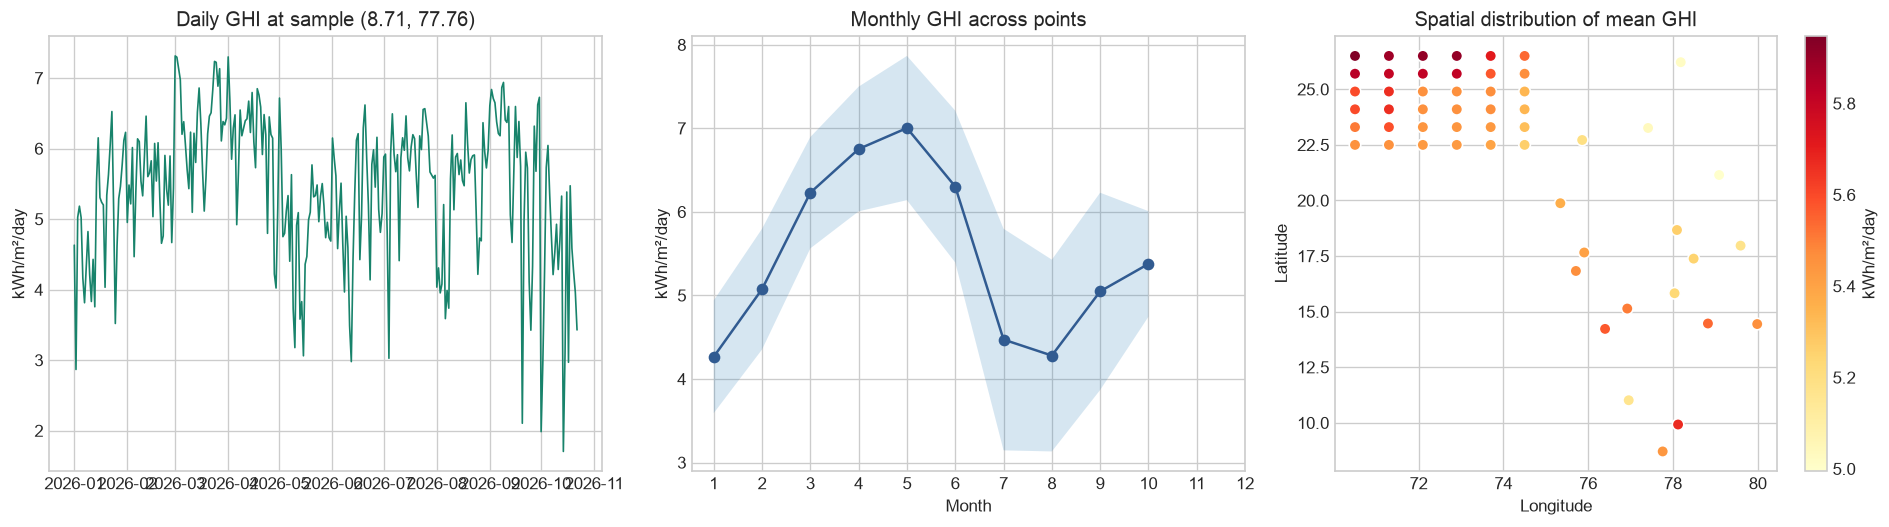

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
# Sample-site time series: GHI (NASA POWER ALLSKY_SFC_SW_DWN, kWh/m²/day).
sample_site = raw.groupby(["lat", "lon"]).size().sort_values(ascending=False).index[0]
sample = raw[(raw.lat == sample_site[0]) & (raw.lon == sample_site[1])].sort_values("date")
axes[0].plot(sample.date, sample.ALLSKY_SFC_SW_DWN, lw=1, color="#18836b")
axes[0].set(title=f"Daily GHI at sample ({sample_site[0]:.2f}, {sample_site[1]:.2f})", ylabel="kWh/m²/day")

monthly = raw.assign(month=raw.date.dt.month).groupby("month").ALLSKY_SFC_SW_DWN.agg(["mean", "median", "std"])
axes[1].plot(monthly.index, monthly["mean"], marker="o", color="#315b91")
axes[1].fill_between(monthly.index, monthly["mean"]-monthly["std"], monthly["mean"]+monthly["std"], alpha=.18)
axes[1].set(title="Monthly GHI across points", xlabel="Month", ylabel="kWh/m²/day", xticks=range(1,13))

site_ghi = raw.groupby(["lat", "lon"]).ALLSKY_SFC_SW_DWN.mean().reset_index()
sc = axes[2].scatter(site_ghi.lon, site_ghi.lat, c=site_ghi.ALLSKY_SFC_SW_DWN, cmap="YlOrRd", s=48, edgecolor="white")
axes[2].set(title="Spatial distribution of mean GHI", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(sc, ax=axes[2], label="kWh/m²/day")
plt.tight_layout()

                   ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN  ALLSKY_KT   T2M  QV2M  RH2M  WS10M  PRECTOTCORR
ALLSKY_SFC_SW_DWN               1.00               0.15       0.11  0.55 -0.29 -0.61   0.05        -0.36
CLRSKY_SFC_SW_DWN               0.15               1.00       0.81  0.01 -0.28 -0.32   0.18        -0.06
ALLSKY_KT                       0.11               0.81       1.00 -0.01 -0.25 -0.29   0.25        -0.02
T2M                             0.55               0.01      -0.01  1.00  0.36 -0.21   0.33         0.00
QV2M                           -0.29              -0.28      -0.25  0.36  1.00  0.82   0.35         0.35
RH2M                           -0.61              -0.32      -0.29 -0.21  0.82  1.00   0.14         0.36
WS10M                           0.05               0.18       0.25  0.33  0.35  0.14   1.00         0.03
PRECTOTCORR                    -0.36              -0.06      -0.02  0.00  0.35  0.36   0.03         1.00


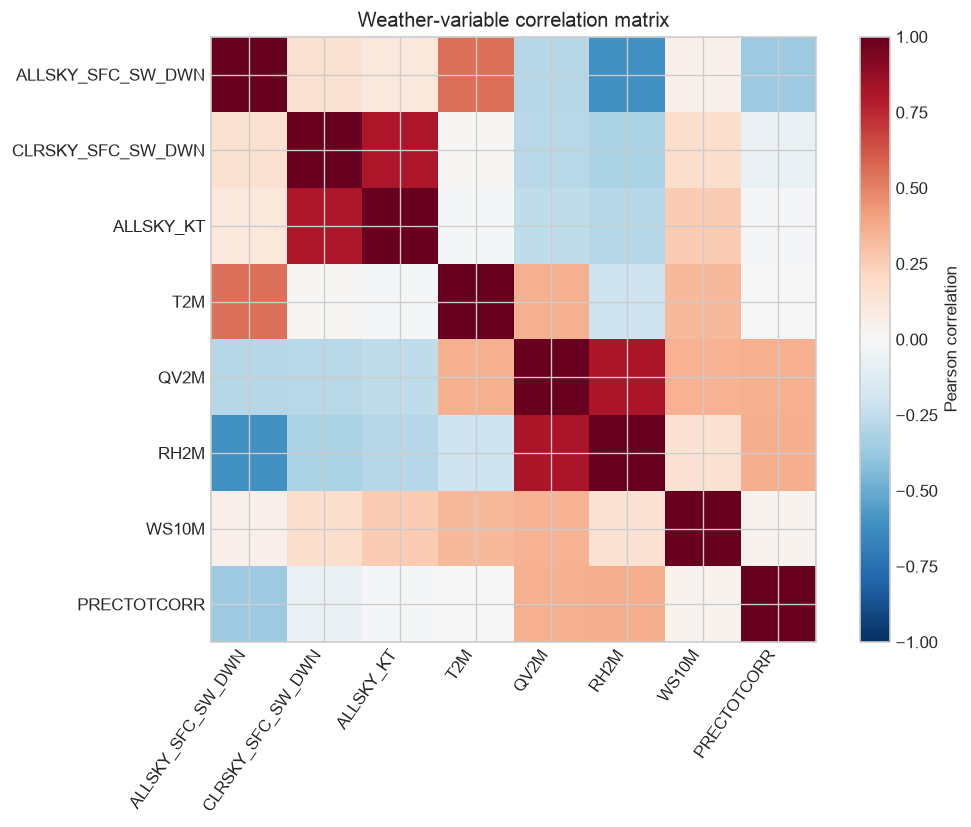

In [6]:
# Correlation is descriptive; it does not establish causal effects.
eda_cols = ["ALLSKY_SFC_SW_DWN", "CLRSKY_SFC_SW_DWN", "ALLSKY_KT", "T2M", "QV2M", "RH2M", "WS10M", "PRECTOTCORR"]
correlations = raw[eda_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_cols)), eda_cols, rotation=55, ha="right")
ax.set_yticks(range(len(eda_cols)), eda_cols)
ax.set_title("Weather-variable correlation matrix")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
display(correlations.round(2))

### What this EDA can and cannot tell us

The partial-year records capture the 2026 weather history in the downloaded window. The seasonal curve is therefore incomplete, and site-to-site differences can be blurred by NASA POWER's gridded spatial resolution. Treat correlations, trends, and spatial rankings as descriptive. The sample count is not a count of candidate parcels.

## 3. Cleaning and feature engineering

Cleaning is done **within each site** after sorting by date. NASA POWER missing sentinels (`≤ -900`) and negative GHI readings are converted to missing values; gaps are linearly interpolated, then edge gaps are forward/back-filled. The operation is site-grouped so one coordinate cannot fill another site's gap.

Solar geometry is summarized with an approximate top-of-atmosphere (TOA) daily irradiance term. The **clearness index** is `GHI / TOA`, clipped to `[0, 1]`, to reduce the seasonal cycle in the target. The next-day target is `clearness_index.shift(-1)` per site. Lag/rolling features are shifted so they use prior observations; rows without a full history or next-day target are dropped.

The deployed feature list is weather (`T2M`, `QV2M`, `RH2M`, `WS10M`, `PRECTOTCORR`), prior clearness lags and rolling mean, day of year, latitude, and longitude. Same-day/future irradiance-derived columns are excluded from the model inputs.

In [7]:
raw = raw.sort_values(["lat", "lon", "date"]).copy()
value_cols = [c for c in raw.columns if c not in ["date", "lat", "lon"]]
raw[value_cols] = raw[value_cols].mask(raw[value_cols] <= -900)
raw.loc[raw["ALLSKY_SFC_SW_DWN"] < 0, "ALLSKY_SFC_SW_DWN"] = np.nan

def clean_one_site(group):
    group = group.sort_values("date").copy().set_index("date")
    group[value_cols] = group[value_cols].interpolate(method="linear").ffill().bfill()
    return group.reset_index()

clean = raw.groupby(["lat", "lon"], group_keys=False).apply(clean_one_site).reset_index(drop=True)
if clean[value_cols].isna().any().any():
    raise ValueError("Missing values remain after per-site cleaning; inspect the affected columns/sites.")
print(f"Cleaned {len(clean):,} rows across {clean[['lat','lon']].drop_duplicates().shape[0]} sites.")
print("Remaining missing weather values:", int(clean[value_cols].isna().sum().sum()))

Cleaned 15,930 rows across 54 sites.
Remaining missing weather values: 0


In [8]:
def toa_irradiance(day_of_year, lat_deg):
    lat_rad = np.radians(lat_deg)
    declination = np.radians(23.45) * np.sin(np.radians(360 / 365 * (day_of_year - 81)))
    solar_constant = 1.367  # kW/m²
    mean_cos_zenith = np.sin(lat_rad) * np.sin(declination) + np.cos(lat_rad) * np.cos(declination)
    mean_cos_zenith = np.clip(mean_cos_zenith, 0.05, 1.0)
    return solar_constant * mean_cos_zenith * 24 / np.pi

featured = clean.copy()
featured["day_of_year"] = featured.date.dt.dayofyear
featured["toa_irradiance"] = toa_irradiance(featured.day_of_year, featured.lat)
featured["clearness_index"] = (featured.ALLSKY_SFC_SW_DWN / featured.toa_irradiance).clip(0, 1)

def add_site_features(group):
    group = group.sort_values("date").copy()
    for lag in [1, 2, 3, 7]:
        group[f"clearness_lag{lag}"] = group.clearness_index.shift(lag)
    group["clearness_roll7_mean"] = group.clearness_index.shift(1).rolling(7).mean()
    group["target_next_day_clearness"] = group.clearness_index.shift(-1)
    return group

featured = featured.groupby(["lat", "lon"], group_keys=False).apply(add_site_features).reset_index(drop=True)
FEATURE_COLS = ["T2M", "QV2M", "RH2M", "WS10M", "PRECTOTCORR", "clearness_lag1", "clearness_lag2", "clearness_lag3", "clearness_roll7_mean", "day_of_year", "lat", "lon"]
TARGET_COL = "target_next_day_clearness"
forbidden = {"ALLSKY_SFC_SW_DWN", "CLRSKY_SFC_SW_DWN", "ALLSKY_KT", "clearness_index", TARGET_COL}
assert forbidden.isdisjoint(FEATURE_COLS), "Potential target leakage: review FEATURE_COLS."
model_df = featured.dropna(subset=FEATURE_COLS + [TARGET_COL]).copy().reset_index(drop=True)
model_df["target_date"] = model_df.date + pd.Timedelta(days=1)
print(f"Model table: {len(model_df):,} rows · {model_df[['lat','lon']].drop_duplicates().shape[0]} sites")
print(f"Feature count: {len(FEATURE_COLS)} · target: {TARGET_COL}")
display(model_df[FEATURE_COLS + [TARGET_COL]].head())

Model table: 15,498 rows · 54 sites
Feature count: 12 · target: target_next_day_clearness
     T2M   QV2M   RH2M  WS10M  PRECTOTCORR  ...  clearness_roll7_mean  day_of_year     lat      lon  target_next_day_clearness
0  22.86  12.97  74.77   5.05         0.00  ...              0.492449            8  8.7139  77.7567                   0.538252
1  23.58  13.61  74.72   5.20         0.01  ...              0.487155            9  8.7139  77.7567                   0.469439
2  24.63  15.03  77.39   3.67         0.53  ...              0.517960           10  8.7139  77.7567                   0.426339
3  25.07  16.50  82.69   3.40         1.74  ...              0.504333           11  8.7139  77.7567                   0.492115
4  24.99  16.05  81.15   3.86         0.34  ...              0.482102           12  8.7139  77.7567                   0.416669


## 4. Chronological forecast validation

A random row split is inappropriate for time series: it can put later dates in training and earlier dates in the test set. Here we divide **target dates** into three chronological blocks: 70% train, 15% interval-calibration, 15% final test. All sites on a date stay on the same side of each cutoff.

We compare the Random Forest with two simple baselines:

- **Persistence:** tomorrow equals today's clearness index. This uses the observation available at the forecast origin.
- **Day-of-year climatology:** the training-set mean target for the same day of year (falls back to the training mean when absent).

The code in `03_train_forecast_model.py` uses `clearness_lag1` for its persistence baseline. Since that feature is already yesterday relative to the feature date, it is two days before the next-day target. This notebook corrects that alignment and states it explicitly so the comparison is fairer.

In [9]:
unique_target_dates = np.sort(model_df.target_date.unique())
cut1 = pd.Timestamp(unique_target_dates[int(len(unique_target_dates) * 0.70)])
cut2 = pd.Timestamp(unique_target_dates[int(len(unique_target_dates) * 0.85)])
train = model_df[model_df.target_date < cut1].copy()
calibration = model_df[(model_df.target_date >= cut1) & (model_df.target_date < cut2)].copy()
test = model_df[model_df.target_date >= cut2].copy()
print(f"Train targets: {train.target_date.min().date()} to {train.target_date.max().date()} ({len(train):,} rows)")
print(f"Calibration targets: {calibration.target_date.min().date()} to {calibration.target_date.max().date()} ({len(calibration):,} rows)")
print(f"Test targets: {test.target_date.min().date()} to {test.target_date.max().date()} ({len(test):,} rows)")
assert train.target_date.max() < calibration.target_date.min() < test.target_date.min()

X_train, y_train = train[FEATURE_COLS], train[TARGET_COL]
X_cal, y_cal = calibration[FEATURE_COLS], calibration[TARGET_COL]
X_test, y_test = test[FEATURE_COLS], test[TARGET_COL]

Train targets: 2026-01-09 to 2026-07-27 (10,800 rows)
Calibration targets: 2026-07-28 to 2026-09-08 (2,322 rows)
Test targets: 2026-09-09 to 2026-10-22 (2,376 rows)


In [10]:
rf = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = np.clip(rf.predict(X_test), 0, 1)

# The deployed training script's fallback: no-intercept linear regression on clearness_lag1.
from sklearn.linear_model import LinearRegression
lag_model = LinearRegression(fit_intercept=False)
lag_model.fit(train[["clearness_lag1"]], y_train)
lag_pred = lag_model.predict(test[["clearness_lag1"]])

# Aligned persistence and seasonal-climatology baselines.
persistence_pred = np.clip(test.clearness_index.to_numpy(), 0, 1)
train_target_doy = train.target_date.dt.dayofyear
climatology = pd.DataFrame({"doy": train_target_doy, "target": y_train}).groupby("doy").target.mean()
climatology_pred = test.target_date.dt.dayofyear.map(climatology).fillna(float(y_train.mean())).to_numpy().clip(0, 1)

def regression_metrics(y, pred):
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "R²": r2_score(y, pred),
    }

point_results = pd.DataFrame({
    "Persistence (today → tomorrow)": regression_metrics(y_test, persistence_pred),
    "Day-of-year climatology": regression_metrics(y_test, climatology_pred),
    "Random Forest": regression_metrics(y_test, rf_pred),
    "Calibrated lag fallback (script)": regression_metrics(y_test, lag_pred),
}).T
point_results["RMSE skill vs persistence"] = 1 - point_results.RMSE / point_results.loc["Persistence (today → tomorrow)", "RMSE"]
# Mirror script selection logic, but compare RF to the correctly aligned persistence baseline.
selected_name = "Random Forest" if point_results.loc["Random Forest", "RMSE"] < point_results.loc["Persistence (today → tomorrow)", "RMSE"] else "Calibrated lag fallback (script)"
print(f"Selected by the script's fallback rule: {selected_name}")
display(point_results.round(4))

Selected by the script's fallback rule: Calibrated lag fallback (script)
                                     MAE    RMSE      R²  RMSE skill vs persistence
Persistence (today → tomorrow)    0.0501  0.0887  0.3003                     0.0000
Day-of-year climatology           0.0688  0.1136 -0.1467                    -0.2802
Random Forest                     0.1245  0.1348 -0.6143                    -0.5189
Calibrated lag fallback (script)  0.0662  0.1082 -0.0409                    -0.2196


                      RMSE increase
PRECTOTCORR                0.016650
clearness_lag1             0.004876
QV2M                       0.003555
lon                        0.000784
clearness_roll7_mean       0.000195
WS10M                      0.000155
day_of_year                0.000000
T2M                       -0.000348
clearness_lag3            -0.000392
RH2M                      -0.000501
lat                       -0.000666
clearness_lag2            -0.001842


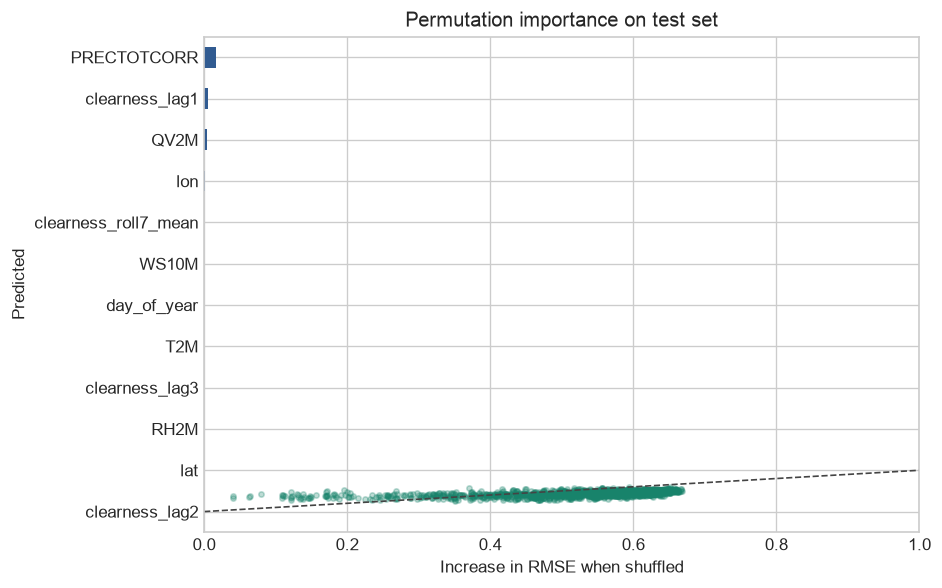

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, rf_pred, s=10, alpha=.28, color="#18836b")
ax.plot([0, 1], [0, 1], "--", color="#444", lw=1)
ax.set(xlim=(0,1), ylim=(0,1), xlabel="Observed next-day clearness index", ylabel="Predicted", title="Random Forest: chronological test predictions")
plt.tight_layout()

# Permutation importance on the held-out test block; importance is predictive, not causal.
from sklearn.inspection import permutation_importance
perm = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values()
ax = importance.plot.barh(figsize=(8, 5), color="#315b91", title="Permutation importance on test set")
ax.set_xlabel("Increase in RMSE when shuffled")
plt.tight_layout()
display(importance.sort_values(ascending=False).to_frame("RMSE increase"))

### Prediction interval calibration

Two quantile Gradient Boosting models estimate the 10th and 90th percentiles. Additive residual quantiles are estimated on the separate calibration block, then applied unchanged to the final test block. Test coverage and mean interval width are reported below. This is preferable to reporting coverage on the same rows used to tune the offsets, which makes the coverage estimate optimistic.

In [12]:
q10 = GradientBoostingRegressor(loss="quantile", alpha=0.10, n_estimators=200, max_depth=4, random_state=SEED)
q90 = GradientBoostingRegressor(loss="quantile", alpha=0.90, n_estimators=200, max_depth=4, random_state=SEED)
q10.fit(X_train, y_train); q90.fit(X_train, y_train)
cal_lo, cal_hi = q10.predict(X_cal), q90.predict(X_cal)
lower_offset = float(np.quantile(y_cal.to_numpy() - cal_lo, 0.10))
upper_offset = float(np.quantile(y_cal.to_numpy() - cal_hi, 0.90))
raw_lo, raw_hi = q10.predict(X_test) + lower_offset, q90.predict(X_test) + upper_offset
interval_lo = np.minimum(np.clip(raw_lo, 0, 1), rf_pred)
interval_hi = np.maximum(np.clip(raw_hi, 0, 1), rf_pred)
covered = (y_test.to_numpy() >= interval_lo) & (y_test.to_numpy() <= interval_hi)
interval_summary = pd.Series({
    "Target coverage": 0.80,
    "Test empirical coverage": covered.mean(),
    "Mean interval width": np.mean(interval_hi - interval_lo),
    "Median interval width": np.median(interval_hi - interval_lo),
    "Lower calibration offset": lower_offset,
    "Upper calibration offset": upper_offset,
})
display(interval_summary.to_frame("value").round(4))

                           value
Target coverage           0.8000
Test empirical coverage   0.6818
Mean interval width       0.2597
Median interval width     0.2583
Lower calibration offset -0.0423
Upper calibration offset  0.0334


### Model-selection and deployment note

The existing training script fits a 300-tree Random Forest and falls back to a one-feature linear lag model if the forest does not beat its persistence baseline. After validation, it refits the selected point model and quantile models on all available rows and saves joblib artifacts. This notebook's three-way split is for honest reporting; deployment retraining should happen only after the validation results are recorded. It uses the same Random Forest hyperparameters and feature set, but its corrected baseline and interval calibration are not identical to the current script.

R² can be negative on a future holdout; that means the model is worse than predicting the test mean under that metric. A positive persistence skill score is a useful headline, but it does not establish generalization to future years or unseen locations.

## 5. Site performance metrics and descriptive regimes

This is a **separate task from next-day forecasting**. Site metrics summarize the available historical solar resource. Estimated daily AC energy uses a simple PVWatts-style first-order calculation for a fixed 1,000 m² reference array:

`daily yield = GHI × 1,000 m² × 20% module efficiency × temperature derate × 0.86 system losses`

The calculation uses the same feature-ready rows as the project’s metric script (the initial lag warm-up and final no-target day are omitted). The output is illustrative energy (kWh/day), not a site-specific plant forecast or quote. Variability is coefficient of variation; seasonal stability is the ratio of the lowest to highest observed monthly mean. With less than a full year, the stability ratio is incomplete.

In [13]:
SYSTEM_AREA_M2, PANEL_EFFICIENCY, SYSTEM_LOSSES = 1000, 0.20, 0.86

def temperature_derate(temp_c):
    return np.where(temp_c > 25, 1 - 0.004 * (temp_c - 25), 1.0)

model_df["daily_yield_kwh"] = clean.ALLSKY_SFC_SW_DWN * SYSTEM_AREA_M2 * PANEL_EFFICIENCY * temperature_derate(clean.T2M) * SYSTEM_LOSSES

def summarize_site(g):
    monthly = g.groupby(g.date.dt.month).daily_yield_kwh.mean()
    mean_yield = g.daily_yield_kwh.mean()
    return pd.Series({
        "mean_daily_yield_kwh": mean_yield,
        "variability_cv": g.daily_yield_kwh.std() / mean_yield if mean_yield else np.nan,
        "seasonal_stability": monthly.min() / monthly.max() if monthly.max() > 0 else np.nan,
    })
site_metrics = model_df.groupby(["lat", "lon"]).apply(summarize_site).reset_index()
display(site_metrics.sort_values("mean_daily_yield_kwh", ascending=False).head(10).round(3))

       lat    lon  mean_daily_yield_kwh  variability_cv  seasonal_stability
50  26.500  72.10               997.645           0.180               0.643
51  26.500  72.90               986.643           0.194               0.594
52  26.500  73.70               985.960           0.194               0.611
45  25.700  73.70               982.882           0.202               0.635
44  25.700  72.90               981.357           0.203               0.611
42  25.700  71.30               975.369           0.206               0.662
53  26.500  74.50               975.131           0.190               0.648
43  25.700  72.10               974.025           0.193               0.642
1    9.925  78.12               969.620           0.169               0.678
46  25.700  74.50               957.514           0.207               0.630


In [14]:
cluster_features = ["mean_daily_yield_kwh", "variability_cv", "seasonal_stability"]
scaler = StandardScaler()
scaled = scaler.fit_transform(site_metrics[cluster_features])
k = min(3, len(site_metrics))
kmeans = KMeans(n_clusters=k, random_state=SEED, n_init=10)
site_metrics["regime_cluster"] = kmeans.fit_predict(scaled)

# Existing labels are ordered by mean yield. They are descriptive buckets,
# not proof that each group is statistically distinct or equally stable.
order = site_metrics.groupby("regime_cluster").mean_daily_yield_kwh.mean().sort_values(ascending=False).index
label_pool = ["Higher resource", "Mid-range resource", "Lower resource"]
label_map = {cluster: label_pool[min(i, len(label_pool)-1)] for i, cluster in enumerate(order)}
site_metrics["regime_label"] = site_metrics.regime_cluster.map(label_map)
print("Regime counts:")
display(site_metrics.regime_label.value_counts().to_frame("sites"))

Regime counts:
                    sites
regime_label             
Lower resource         26
Mid-range resource     14
Higher resource        14


## 6. AHP suitability scoring and rank robustness

The project's ranking combines three criteria: mean daily yield (higher is better), variability (lower is better), and seasonal stability (higher is better). Pairwise judgments use Saaty's 1–9 scale. The normalized-column/row-average method produces weights; the consistency ratio checks whether judgments are internally coherent (`CR < 0.10` is commonly used as a practical threshold).

Scores min-max normalize each metric using the 5th and 95th percentiles, clip tails, invert the lower-is-better variability metric, weight, and scale to 0–100. This is a **weather-resource score**. The current `excluded` flag is always false because no parcel-level hard exclusion dataset is wired into this scoring step. A 200-trial Dirichlet perturbation estimates how often each site lands in the top third under nearby weights; it is not a probability of project success.

In [15]:
criteria = ["mean_daily_yield_kwh", "variability_cv", "seasonal_stability"]
higher_is_better = {criteria[0]: True, criteria[1]: False, criteria[2]: True}
pairwise = np.array([[1, 3, 3], [1/3, 1, 1], [1/3, 1, 1]], dtype=float)
weights = (pairwise / pairwise.sum(axis=0)).mean(axis=1)
n = len(criteria)
lambda_max = ((pairwise @ weights) / weights).mean()
ci = (lambda_max - n) / (n - 1)
ri = {1: 0, 2: 0, 3: 0.58, 4: 0.90, 5: 1.12}.get(n, 1.12)
cr = ci / ri if ri else 0
weight_table = pd.DataFrame({"criterion": criteria, "weight": weights, "direction": ["higher is better" if higher_is_better[c] else "lower is better" for c in criteria]})
display(weight_table)
print(f"Consistency ratio: {cr:.4f} — {'acceptable (< 0.10)' if cr < 0.10 else 'review pairwise judgments'}")

normalized = pd.DataFrame(index=site_metrics.index)
for c in criteria:
    lo, hi = site_metrics[c].quantile(.05), site_metrics[c].quantile(.95)
    v = ((site_metrics[c] - lo) / (hi - lo + 1e-9)).clip(.05, 1.0)
    normalized[c] = v if higher_is_better[c] else (1-v).clip(.05, 1.0)
site_metrics["suitability_score"] = (normalized[criteria].to_numpy() @ weights) * 100
site_metrics["excluded"] = False

N_TRIALS = 200
top_k = max(1, len(site_metrics) // 3)
rank_counts = np.zeros(len(site_metrics))
rng = np.random.default_rng(SEED)
for _ in range(N_TRIALS):
    perturbed = rng.dirichlet(weights * 10)
    scores = normalized[criteria].to_numpy() @ perturbed
    rank_counts[np.argsort(scores)[-top_k:]] += 1
site_metrics["top_k_freq"] = rank_counts / N_TRIALS
ranking = site_metrics.sort_values("suitability_score", ascending=False).reset_index(drop=True)
display(ranking[["lat", "lon", "suitability_score", "top_k_freq", "regime_label"]].head(10).round(3))

              criterion  weight         direction
0  mean_daily_yield_kwh     0.6  higher is better
1        variability_cv     0.2   lower is better
2    seasonal_stability     0.2  higher is better
Consistency ratio: 0.0000 — acceptable (< 0.10)
      lat     lon  suitability_score  top_k_freq        regime_label
0  26.500  72.100             94.764         1.0     Higher resource
1  25.700  73.700             90.737         1.0     Higher resource
2  26.500  73.700             90.695         1.0     Higher resource
3   9.925  78.120             89.789         1.0     Higher resource
4  26.500  74.500             89.566         1.0     Higher resource
5  26.500  72.900             89.262         1.0     Higher resource
6  25.700  71.300             88.208         1.0     Higher resource
7  25.700  72.100             87.973         1.0     Higher resource
8  25.700  72.900             87.799         1.0     Higher resource
9  14.225  76.398             78.023         1.0  Mid-range re

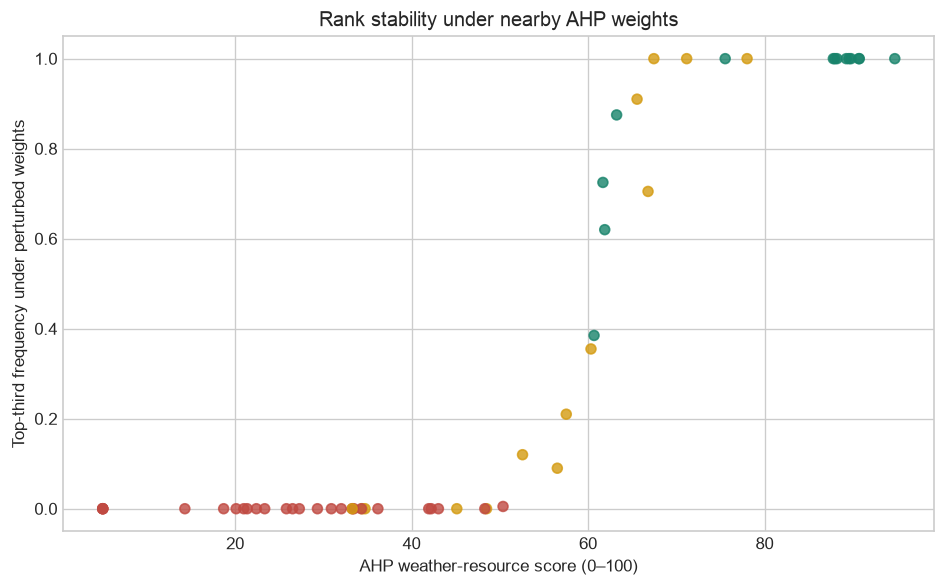

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ranking.regime_label.map({"Higher resource":"#18836b", "Mid-range resource":"#d49b11", "Lower resource":"#c04a42"})
ax.scatter(ranking.suitability_score, ranking.top_k_freq, c=colors, s=35, alpha=.8)
ax.set(xlabel="AHP weather-resource score (0–100)", ylabel="Top-third frequency under perturbed weights", title="Rank stability under nearby AHP weights", ylim=(-.05, 1.05))
plt.tight_layout()

## 7. Model and scoring results — interpretation

The cells above calculate actual holdout metrics and the current AHP ranking from the bundled raw data. Report **MAE, RMSE, R², persistence skill, test interval coverage, and interval width together**; no single number is enough. If the Random Forest does not outperform aligned persistence, the data do not show that its added complexity improves next-day prediction for this holdout. In this run, even the script’s calibrated-lag fallback is worse than persistence, so the simplest persistence forecast is the strongest tested point predictor.

For site selection, use the score to compare the sampled weather resource only. Before treating a location as feasible, add parcel boundaries/title, slope and terrain, grid capacity and interconnection distance, exclusions, protected habitats, permits, land cost, and project economics from authoritative sources.

## 8. App-style forecast precompute

The live app does not retrain models per map click. The project trains offline, then precomputes a next-day clearness forecast for every known point. This cell mirrors that inference pattern: refit the selected point model and quantile models on all available rows **after validation**, select each site's latest feature row, and create one forecast record per site. The validation metrics above remain based on the untouched test window.

In [17]:

# Final refit for inference after the test metrics are recorded.
if selected_name == "Random Forest":
    deployment_model = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=SEED, n_jobs=-1)
    deployment_model.fit(model_df[FEATURE_COLS], model_df[TARGET_COL])
else:
    deployment_model = LinearRegression(fit_intercept=False)
    deployment_model.fit(model_df[["clearness_lag1"]], model_df[TARGET_COL])

deployment_q10 = GradientBoostingRegressor(loss="quantile", alpha=.10, n_estimators=200, max_depth=4, random_state=SEED).fit(model_df[FEATURE_COLS], model_df[TARGET_COL])
deployment_q90 = GradientBoostingRegressor(loss="quantile", alpha=.90, n_estimators=200, max_depth=4, random_state=SEED).fit(model_df[FEATURE_COLS], model_df[TARGET_COL])
latest = model_df.sort_values("date").groupby(["lat", "lon"], as_index=False).tail(1).copy()
if selected_name == "Random Forest":
    app_point = deployment_model.predict(latest[FEATURE_COLS])
else:
    app_point = deployment_model.predict(latest[["clearness_lag1"]])
app_low = np.clip(deployment_q10.predict(latest[FEATURE_COLS]) + lower_offset, 0, 1)
app_high = np.clip(deployment_q90.predict(latest[FEATURE_COLS]) + upper_offset, 0, 1)
app_low = np.minimum(app_low, app_point.clip(0, 1))
app_high = np.maximum(app_high, app_point.clip(0, 1))
app_forecasts = pd.DataFrame({
    "lat": latest.lat.to_numpy(), "lon": latest.lon.to_numpy(),
    "forecast_for": (latest.date + pd.Timedelta(days=1)).dt.date,
    "next_day_clearness": np.clip(app_point, 0, 1),
    "interval_80_lower": app_low, "interval_80_upper": app_high,
})
display(app_forecasts.head(10).round(3))
print(f"Created {len(app_forecasts)} static forecast records using {selected_name}.")


         lat     lon forecast_for  next_day_clearness  interval_80_lower  interval_80_upper
7748   23.30  72.900   2026-10-22               0.610              0.476              0.658
14923  26.50  72.900   2026-10-22               0.595              0.524              0.659
6600   23.26  77.413   2026-10-22               0.532              0.472              0.656
6313   22.72  75.858   2026-10-22               0.493              0.416              0.639
6026   22.50  74.500   2026-10-22               0.512              0.471              0.656
5739   22.50  73.700   2026-10-22               0.576              0.501              0.655
5452   22.50  72.900   2026-10-22               0.602              0.514              0.660
5165   22.50  72.100   2026-10-22               0.602              0.516              0.661
4878   22.50  71.300   2026-10-22               0.618              0.521              0.665
4591   22.50  70.500   2026-10-22               0.612              0.503        

## 9. Export reproducible tables and deployment artifacts (optional)

The default is **not** to overwrite files. Set `SAVE_OUTPUTS = True` to write this notebook's cleaned feature table, site ranking, and validation summary under `files/notebook_outputs/`. The exported model is trained on all rows after validation, for inference only. Its holdout metrics must remain the reported evaluation.

In [18]:
SAVE_OUTPUTS = False
if SAVE_OUTPUTS:
    import joblib
    out_dir = DATA_DIR / "notebook_outputs"
    out_dir.mkdir(parents=True, exist_ok=True)


    featured.to_csv(out_dir / "features_table.csv", index=False)
    ranking.to_csv(out_dir / "site_ranking.csv", index=False)
    app_forecasts.to_csv(out_dir / "site_forecasts.csv", index=False)
    point_results.to_csv(out_dir / "forecast_holdout_metrics.csv")
    joblib.dump(deployment_model, out_dir / "forecast_model.joblib")
    joblib.dump(deployment_q10, out_dir / "forecast_lower.joblib")
    joblib.dump(deployment_q90, out_dir / "forecast_upper.joblib")
    (out_dir / "forecast_interval_offsets.json").write_text(json.dumps({"lower": lower_offset, "upper": upper_offset, "holdout_coverage": float(covered.mean())}, indent=2))
    print(f"Wrote reproducible outputs to {out_dir}")
else:
    print("No files written. Set SAVE_OUTPUTS=True to export tables and fitted inference models.")

No files written. Set SAVE_OUTPUTS=True to export tables and fitted inference models.


## 10. Limitations and next ML improvements

1. **More history:** collect multiple years and rerun a rolling-origin evaluation; one partial year is too little to assess seasonality or year-to-year weather variation.
2. **Spatial validation:** test on held-out locations as well as later dates; current temporal validation contains the same coordinate samples in train and test.
3. **Feature alignment:** retain target date explicitly and ensure all predictors are available at the exact time the forecast is issued. Revisit whether same-day weather is known at prediction time.
4. **Baseline and calibration:** keep persistence aligned to the forecast origin and reserve a separate calibration window (or use a formal conformal method) before measuring interval coverage.
5. **Scoring:** examine sensitivity to AHP judgments and normalization bounds; include verified non-weather constraints only when authoritative data are available.
6. **Uncertainty:** report site-level data coverage and uncertainty alongside scores; NASA POWER's coarse grid cannot distinguish nearby parcels.